# Tennis constructions A/B/C: real prototypes and CPU diagnostics

Executed locally, October 15, 2026. This notebook reuses the source audit and leaves the successful Colab notebook 02 unchanged.
Scores here are **TF-IDF/logistic regression**, not MulTaBench or E5/TAR. No GPU training is launched.
Full text CSVs and schemas stay outside Git; samples below preserve source identities without publishing interview answers.


**Current A follow-up:** this notebook preserves the original A/B/C and v0 review results.
Updated [notebook 05](03_tennis_interview_validation.ipynb) compares six A passage policies, constructs 3,627
rows under a declared three-day calendar-delay assumption, runs training/development CPU diagnostics and records
the full leakage audit. Unknown upload times are documented assumptions rather than an automatic research blocker.
The official implementation and notebook 02 remain unchanged; no outreach or push occurred.


In [1]:
import json
from pathlib import Path
import sys
project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tennis/scripts").is_dir())
if str(project) not in sys.path: sys.path.insert(0, str(project))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tennis.scripts.common import OUT, PRIVATE
audit = json.loads((OUT / "cornell_audit.json").read_text())
joins = json.loads((OUT / "join_summary.json").read_text())
extra = json.loads((OUT / "additional_audit.json").read_text())
meta = pd.read_csv(OUT / "cornell_interview_metadata.csv")


,variant,rows,unique_matches,players,structured_columns,text_columns,date_min,date_max,text_unique,median_words,duplicate_text_fraction
0,A,4052,4052,288,16,2,2007-01-19,2015-11-22,"{'player_a_text': 2616, 'player_b_text': 2637}","{'player_a_text': 300.0, 'player_b_text': 300.0}","{'player_a_text': 0.35439289239881505, 'player..."
1,B,415,415,64,16,2,2015-06-12,2015-11-22,"{'player_a_text': 110, 'player_b_text': 106}","{'player_a_text': 47.0, 'player_b_text': 47.0}","{'player_a_text': 0.7349397590361441, 'player_..."
2,C,44359,44359,1556,10,1,2006-12-31,2015-11-22,{'context_text': 342},{'context_text': 23.0},{'context_text': 0.9922901778669491}


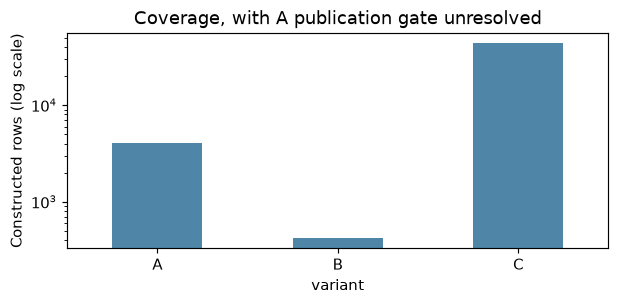

In [2]:
stats=pd.read_json(OUT/"variant_statistics.json")
display(stats[["variant","rows","unique_matches","players","structured_columns","text_columns","date_min","date_max","text_unique","median_words","duplicate_text_fraction"]])
stats.set_index("variant")["rows"].plot.bar(figsize=(6,3),color="#4f86a8",rot=0,logy=True)
plt.ylabel("Constructed rows (log scale)");plt.title("Coverage, with A publication gate unresolved");plt.tight_layout();plt.show()


**Insight:** A has 4,052 provisional two-interview rows; B has 415 snapshot-valid tactical rows; C has 44,359 verbalization rows.
These are different populations. A has zero independently publication-certified rows, so its numerical size does not mean it is cleared for modeling.
B's fixed historical snapshot is much smaller than today's retrospective chart archive.


In [3]:
for variant in ["A","B","C"]:
    print("Variant",variant)
    df=pd.read_csv(PRIVATE/f"variant_{variant}.csv")
    manifest=json.loads((PRIVATE/f"variant_{variant}_schema.json").read_text())
    cols=["match_id","match_date","player_a","player_b","a_rank","b_rank","target"]
    source_cols=[c for c in df if c.endswith("interview_id") or c.endswith("source_match_ids") or c=="source_available_at"]
    examples=df[cols+source_cols].head(3).copy()
    examples["prediction_cutoff"]=examples.match_date.map(lambda day:"Before reported day "+day+"; same-day evidence excluded")
    display(examples)
    print("Structured:",manifest["structured_columns"])
    print("Text:",manifest["text_columns"])
    print("Private 50-row CSV:",PRIVATE/f"variant_{variant}_sample50.csv")
    if variant=="A":print("Interview answers withheld from public notebook outputs pending rights/timing review.")
    elif variant=="B":print("One measured-template example:",df.player_a_text.iloc[0])
    else:print("One context-verbalization example:",df.context_text.iloc[0])


Variant A


,match_id,match_date,player_a,player_b,a_rank,b_rank,target,a_interview_id,b_interview_id,prediction_cutoff
0,5448523514d095bee50ad237,2007-01-19,Roddick A.,Safin M.,7.0,27.0,1,742,741,Before reported day 2007-01-19; same-day evide...
1,c89b7f7020cb3b9e0cc645d4,2007-01-20,Gonzalez F.,Hewitt L.,9.0,19.0,1,736,734,Before reported day 2007-01-20; same-day evide...
2,1c03ee62c5e791ebcc00f5c8,2007-01-21,Williams S.,Jankovic J.,81.0,11.0,1,717,722,Before reported day 2007-01-21; same-day evide...


Structured: ['a_rank', 'b_rank', 'a_prior_n', 'b_prior_n', 'a_form10', 'b_form10', 'a_surface_rate', 'b_surface_rate', 'a_rest_days', 'b_rest_days', 'gender', 'surface', 'court', 'level', 'round', 'best_of']
Text: ['player_a_text', 'player_b_text']
Private 50-row CSV: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/variant_A_sample50.csv
Interview answers withheld from public notebook outputs pending rights/timing review.
Variant B


,match_id,match_date,player_a,player_b,a_rank,b_rank,target,a_source_match_ids,b_source_match_ids,source_available_at,prediction_cutoff
0,26f4850121711194eb251eb8,2015-06-12,Groth S.,Troicki V.,66.0,28.0,0,20140710-M-Newport-QF-Samuel_Groth-Nicolas_Mah...,20141018-M-Vienna-SF-Viktor_Troicki-Andy_Murra...,2015-06-11T16:38:31Z,Before reported day 2015-06-12; same-day evide...
1,752dc201c0988ea974dcf872,2015-06-12,Kohlschreiber P.,Monfils G.,29.0,16.0,0,20150210-M-Rotterdam-R32-Vasek_Pospisil-Philip...,20141030-M-Paris_Masters-R16-Novak_Djokovic-Ga...,2015-06-11T16:38:31Z,Before reported day 2015-06-12; same-day evide...
2,881406f4380ae2749be00df3,2015-06-12,Nadal R.,Tomic B.,10.0,24.0,1,20140612-M-Halle-R16-Dustin_Brown-Rafael_Nadal...,20140625-M-Wimbledon-R64-Tomas_Berdych-Bernard...,2015-06-11T16:38:31Z,Before reported day 2015-06-12; same-day evide...


Structured: ['a_rank', 'b_rank', 'a_prior_n', 'b_prior_n', 'a_form10', 'b_form10', 'a_surface_rate', 'b_surface_rate', 'a_rest_days', 'b_rest_days', 'gender', 'surface', 'court', 'level', 'round', 'best_of']
Text: ['player_a_text', 'player_b_text']
Private 50-row CSV: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/variant_B_sample50.csv
One measured-template example: In 2 earlier charted matches within the preceding year, this player had 160 direction-coded serves. Wide deliveries accounted for 30.0%, T deliveries for 34.4%, and middle deliveries for 35.6%. These are placement frequencies among direction-coded serves, not serve success rates. No injury or psychological assessment is available.
Variant C


,match_id,match_date,player_a,player_b,a_rank,b_rank,target,prediction_cutoff
0,075f9dd713632ad2f63c40b3,2006-12-31,Benesova I.,Bremond S.,58.0,40.0,0,Before reported day 2006-12-31; same-day evide...
1,102cd3008ab9d92e12487638,2006-12-31,Castano C.,Golds S.,54.0,599.0,1,Before reported day 2006-12-31; same-day evide...
2,2d729201e11f2e79e31c2d6d,2006-12-31,Camerin M.E.,Vesnina E.,50.0,47.0,0,Before reported day 2006-12-31; same-day evide...


Structured: ['a_rank', 'b_rank', 'a_prior_n', 'b_prior_n', 'a_form10', 'b_form10', 'a_surface_rate', 'b_surface_rate', 'a_rest_days', 'b_rest_days']
Text: ['context_text']
Private 50-row CSV: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/variant_C_sample50.csv
One context-verbalization example: This women's match is on hard in outdoor conditions. It is the 1st Round at Tier 3 level, played as best of 3 sets.


A uses previous player answers, clipped to the first 300 words per side, with questions retained separately in the private source.
B's sentences describe wide/T/middle serve-placement frequencies from old charts; they do not claim forehand quality, injuries or psychology.
C moves gender/surface/court/level/round/best-of into text and removes those fields from structured input.
Source IDs, match dates and winner/loser source roles never enter model predictors.
A raw point-log prefix contains 292 complete points from two matches; its 8 nonempty Notes are terse challenge annotations,
not a verified analysis corpus. This bounded prefix cannot estimate the full project's note quality or prevalence.


In [4]:
missing=pd.read_csv(OUT/"feature_missingness.csv")
display(missing[missing.missing_fraction>0].sort_values(["variant","missing_fraction"],ascending=[True,False]))
display(pd.read_csv(OUT/"prototype_text_profiles.csv"))
print("No whole-dataset numerical imputation was applied; diagnostic imputation fits training data only.")


,variant,column,missing_fraction
7,A,b_surface_rate,0.003208
6,A,a_surface_rate,0.002715
22,B,a_surface_rate,0.002410
38,C,a_surface_rate,0.038234
39,C,b_surface_rate,0.036453
36,C,a_form10,0.017336
40,C,a_rest_days,0.017336
37,C,b_form10,0.017201
41,C,b_rest_days,0.017201
32,C,a_rank,0.001781


,variant,column,rows,unique_texts,words_min,words_p10,words_median,words_p90,words_max
0,A,player_a_text,4052,2616,71,252.0,300.0,300.0,300
1,A,player_b_text,4052,2637,71,248.0,300.0,300.0,300
2,B,player_a_text,415,110,47,47.0,47.0,47.0,47
3,B,player_b_text,415,106,47,47.0,47.0,47.0,47
4,C,context_text,44359,342,22,22.0,23.0,24.0,24


No whole-dataset numerical imputation was applied; diagnostic imputation fits training data only.


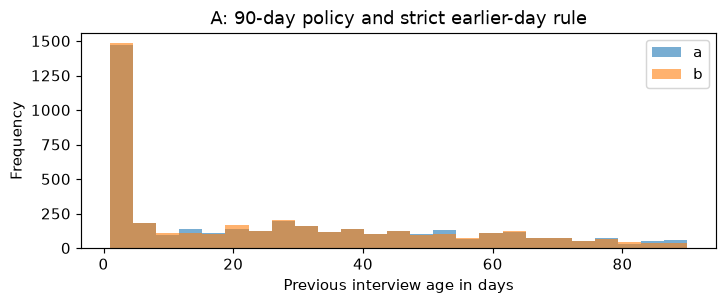

No/one/two recent sides before completed-target filtering: {'0_sides': 26932, '1_sides': 14967, '2_sides': 4255}
Player-centric unique next-match candidates: 5067


In [5]:
a=pd.read_csv(PRIVATE/"variant_A.csv")
gaps=pd.DataFrame({side:(pd.to_datetime(a.match_date)-pd.to_datetime(a[f"{side}_text_date"])).dt.days for side in ["a","b"]})
gaps.plot.hist(bins=25,alpha=.6,figsize=(7,3))
plt.xlabel("Previous interview age in days");plt.title("A: 90-day policy and strict earlier-day rule");plt.tight_layout();plt.show()
print("No/one/two recent sides before completed-target filtering:",joins["a_interview_sides_coverage"])
print("Player-centric unique next-match candidates:",extra["playercentric_unique_target_matches"])


**Insight:** Median source age is 19 days, and a fixed 90-day limit prevents indefinite profile reuse.
This validates the implemented day rule, not publication availability. The player-centric alternative changes coverage and must deduplicate target matches.
Neither larger candidate count resolves that timing/licensing gate.


,cohort,condition,auroc,n_train,n_test,cutoff,runtime_seconds,rss_mb_after_fit
0,B_same415,structured,0.8128,328,87,2015-10-20,0.0212,248.5780
1,B_same415,text_tfidf,0.6026,328,87,2015-10-20,0.0197,249.2826
2,B_same415,joint_tfidf,0.7990,328,87,2015-10-20,0.0276,249.3153
3,B_same415,all_numeric_tactics_control,0.7980,328,87,2015-10-20,0.0081,249.3645
4,B_same415,joint_shuffled_train_text,0.8012,328,87,2015-10-20,0.0292,250.8882
5,C_same415,structured,0.8330,328,87,2015-10-20,0.0046,250.9210
6,C_same415,text_tfidf,0.4584,328,87,2015-10-20,0.0081,251.0029
7,C_same415,joint_tfidf,0.8208,328,87,2015-10-20,0.0093,251.0684
8,C_same415,all_structured_context_control,0.8128,328,87,2015-10-20,0.0075,251.1012
9,C_same415,joint_shuffled_train_text,0.8256,328,87,2015-10-20,0.0104,251.1503


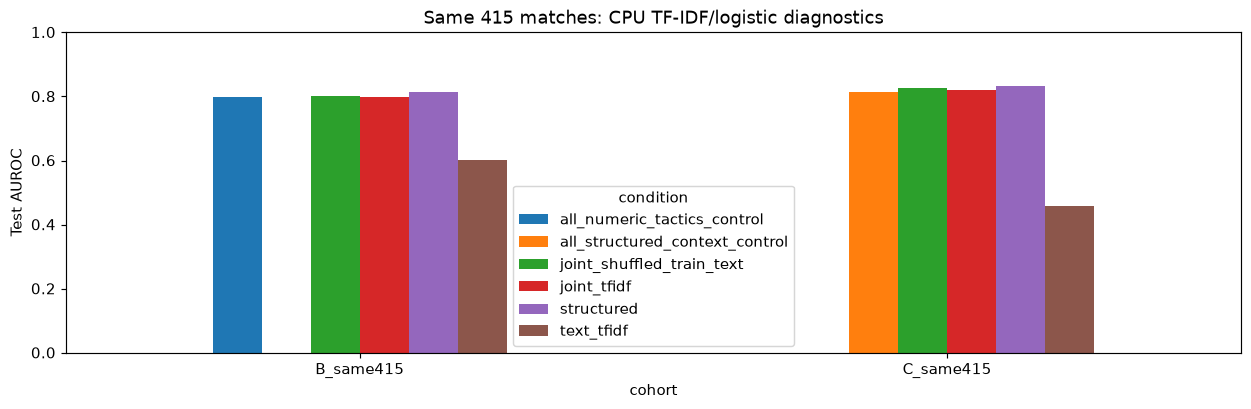

In [6]:
results=pd.read_csv(OUT/"diagnostic_scores.csv")
display(results[["cohort","condition","auroc","n_train","n_test","cutoff","runtime_seconds","rss_mb_after_fit"]].round(4))
common=results[results.cohort.isin(["B_same415","C_same415"])]
common.pivot(index="cohort",columns="condition",values="auroc").plot.bar(figsize=(12,4),rot=0)
plt.ylim(0,1);plt.ylabel("Test AUROC");plt.title("Same 415 matches: CPU TF-IDF/logistic diagnostics");plt.tight_layout();plt.show()


**Insight:** Neither B nor C improves the joint score over its stronger unimodal baseline on this split.
B's raw-numeric tactical control performs similarly to its verbalized joint condition. C's full-structured-context control equals B's structured baseline.
This is a small chronological diagnostic; it neither proves impossibility nor supplies official curation evidence.
The separate C-latest1500 scores use another population and should not be ranked directly against B as a fair construction comparison.


In [7]:
display(results[["cohort","condition","detected_text_on_fit_pool"]].drop_duplicates())
print("All A/B/C calendar intersection:",joins["common_ABC_rows"])
print("A strict publication-verified rows:",joins["a_strict_publication_verified_rows"])
print("TAR scores: unavailable; no GPU diagnostic was run.")
print("Local predictions and chronological split IDs are in",OUT)


,cohort,condition,detected_text_on_fit_pool
0,B_same415,structured,"{""player_a_text"": false, ""player_b_text"": false}"
1,B_same415,text_tfidf,"{""player_a_text"": false, ""player_b_text"": false}"
2,B_same415,joint_tfidf,"{""player_a_text"": false, ""player_b_text"": false}"
3,B_same415,all_numeric_tactics_control,"{""player_a_text"": false, ""player_b_text"": false}"
4,B_same415,joint_shuffled_train_text,"{""player_a_text"": false, ""player_b_text"": false}"
5,C_same415,structured,"{""context_text"": false}"
6,C_same415,text_tfidf,"{""context_text"": false}"
7,C_same415,joint_tfidf,"{""context_text"": false}"
8,C_same415,all_structured_context_control,"{""context_text"": false}"
9,C_same415,joint_shuffled_train_text,"{""context_text"": false}"


All A/B/C calendar intersection: 104
A strict publication-verified rows: 0
TAR scores: unavailable; no GPU diagnostic was run.
Local predictions and chronological split IDs are in /Users/dimabshara/Desktop/NLP/text-tabular-research-2/research/data/tennis_prototypes


**Insight:** The pinned detector requires at least 100 distinct strings or a uniqueness ratio ≥0.8.
B/C pass on their full populations but fail on the measured chronological training subsets.
Our explicitly forced TF-IDF diagnostic is therefore not proof the official pipeline would use E5.
We do not modify the detector or add artificial IDs. A's timing gate remains unresolved and A has no model score.


## Prepared A100 diagnostic, deferred pending review

Reuse notebook 02's setup cells and isolated `/content/multabench-env` environment; do not replace its working smoke-test CSV or training cells.
After review, upload the relevant private CSV/schema and our new `tennis/scripts/tennis_temporal_pilot.py` (plus existing `colab_runner.py`) to your private Colab project.
No new files are available from GitHub until a push is explicitly approved.

First check, without training:

```python
command([str(BENCH_PY), "-u", str(PROJECT / "tennis/scripts/tennis_temporal_pilot.py"),
         "--reference", str(REFERENCE), "--csv", "/content/tennis-private/variant_A.csv",
         "--schema", "/content/tennis-private/variant_A_schema.json", "--output", str(OUTPUT / "interview-pilot")])
```

Current A will stop at publication validation. Current B/C will stop at actual official fitting-pool text detection.
Do not spend GPU time on those known blockers. If the gates are genuinely resolved and GPU work is approved, append `--run`.
That uses unchanged official LightGBM/E5/TAR/metrics with four conditions, a chronological outer holdout and two TAR epochs/batch 32.
It is a diagnostic departure from the five-random-holdout protocol; results must keep that label.

**Recommendation:** prioritize A's source availability/rights and a small independent transcript-identity audit.
B is currently weak as the main NLP direction; C is a control. If A's gates remain unresolved, pivot away from tennis rather than force passage.


## Practical review of interview candidate A

The local review export separates model inputs, audit metadata and chronological roles. Its text-bearing files
and an executed workbench with three concise real examples stay outside Git in
`tennis-research-cache/derived/candidate_A_v0_review/` (a sibling cache of this repository).
This section displays metadata only. No new sources, model fits or outreach are part of this step.


Private workbench: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/candidate_A_v0_review/candidate_workbench.ipynb
Private feature CSV: /Users/dimabshara/Desktop/NLP/tennis-research-cache/derived/candidate_A_v0_review/features.csv


,rows,structured,text,unique_interviews,new_model_fits
0,4052,16,2,4171,0


,split,rows,first_day,last_day,a_wins,b_wins,current_targets_referenced_by_earlier_partitions
0,train,2430,2007-01-19,2012-10-12,1220,1210,0
1,development,809,2012-10-13,2014-06-18,374,435,0
2,reserved_test,813,2014-06-19,2015-11-22,414,399,0


,topic,scope,documents_with_cue_in_full,documents_with_cue_in_first300,documents_with_cue_only_after_first300,fraction_of_full_cue_documents_lost
0,condition,training_partition_interviews_only,1296,755,541,0.417438
1,tactics,training_partition_interviews_only,1584,1076,508,0.320707
2,surface,training_partition_interviews_only,1032,546,486,0.470930


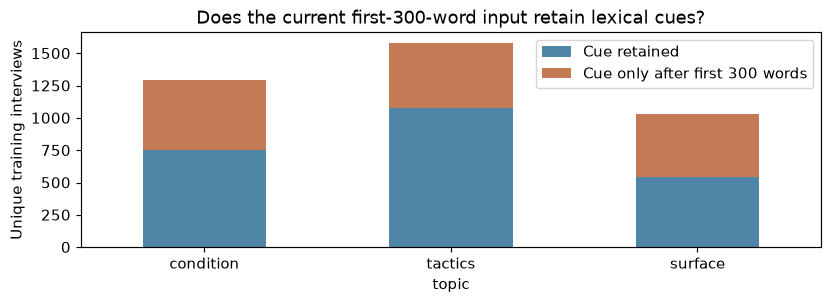

In [8]:
review_file = OUT / "interview_candidate_review.json"
if review_file.exists():
    review = json.loads(review_file.read_text())
    print("Private workbench:", PRIVATE / "candidate_A_v0_review/candidate_workbench.ipynb")
    print("Private feature CSV:", PRIVATE / "candidate_A_v0_review/features.csv")
    display(pd.DataFrame([{"rows":review["rows"], "structured":review["structured_columns"],
        "text":review["text_columns"], "unique_interviews":review["unique_interviews"], "new_model_fits":0}]))
    display(pd.read_csv(OUT / "interview_candidate_split_plan.csv"))
    clip = pd.read_csv(OUT / "interview_candidate_clipping_summary.csv")
    display(clip)
    ax = clip.set_index("topic")[["documents_with_cue_in_first300", "documents_with_cue_only_after_first300"]].plot.bar(
        stacked=True,figsize=(8,3),rot=0,color=["#4f86a8","#c47a55"])
    ax.set(ylabel="Unique training interviews",title="Does the current first-300-word input retain lexical cues?")
    ax.legend(["Cue retained", "Cue only after first 300 words"])
    plt.tight_layout();plt.show()
else:
    print("Prepare this optional local review: python3 -m tennis.scripts.prepare_interview_review")


**Insight:** of 1,296 training-source interviews with a condition-related lexical cue, 541 (41.7%) have no such cue
in the first 300 words. These counts are screening indicators, not verified injury labels or model results.
Fixed clipping may discard potentially relevant language. Passage-policy decisions should use training data,
preserve provenance and respect the official token limit; multi-chunk embedding pooling is not silently added.

The review keeps 16 structured columns, two real-text columns and the outcome; `match_id` is audit-only.
The chronological plan has 2,430 training, 809 development and 813 reserved-test rows, with whole dates kept together.
This fixes the reverse-time interview-source route across those partitions but does not certify historical publication.
Source-use and availability statuses remain explicit. No email or other outreach is part of the current work.
